#### Definição das variáveis de interesse da separação por perfil de município

1. Eliminação de Multicolinearidade

2. Análise de Componentes Principais (PCA)

3. Selecionar os mais fortes no ranking da PCA 

In [1]:
from pathlib import Path
import pandas as pd

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Processada.csv"

df = pd.read_csv(file_path)

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,SDG16_CRP,Normalizado (0-100): SDG16_CRP,SDG16_DRTHMN,Normalizado (0-100): SDG16_DRTHMN,SDG16_TRANSP,Normalizado (0-100): SDG16_TRANSP,SDG17_1_INVST_PB,Normalizado (0-100): SDG17_1_INVST_PB,SDG17_3_P_RC_TRB,Normalizado (0-100): SDG17_3_P_RC_TRB
0,21495.0,41.885064,53.769451,53.255278,66.451721,58.730307,20.177142,56.309444,46.940699,11.631238,...,85.714,85.714,42.857,42.857,66.667,66.667,13.216,0.000000,5.257,8.108054
1,96833.0,45.475390,54.219225,50.890756,65.677811,41.654565,72.408554,68.007222,49.281375,14.603964,...,85.714,85.714,57.143,57.143,66.667,66.667,85.642,1.133196,18.394,34.298246
2,5363.0,47.569518,49.228293,43.817398,89.494428,48.938353,44.025511,63.241944,54.613778,7.181381,...,85.714,85.714,42.857,42.857,66.667,66.667,909.852,38.715329,5.686,8.963317
3,86895.0,48.582323,50.752090,51.083977,73.026011,47.023041,66.630268,69.962222,45.581682,17.049953,...,85.714,85.714,57.143,57.143,50.000,50.000,328.073,12.187507,21.627,40.743620
4,15890.0,48.718897,56.552994,50.268036,79.958615,32.086768,65.794541,68.762222,52.890151,11.397874,...,100.000,100.000,42.857,42.857,66.667,66.667,246.352,8.461212,12.178,21.905901


- Cálculo de correlação média de cada variável com relação a toda a base 
- Para cada par com correlação > 0.80, descarta a variável mais redundante do par, ou seja a que contém a maior correlação média com o restante, em vez de simplesmente a que aparece primeiro na ordem das colunas do DataFrame

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cols_to_keep = [c for c in df.columns if c.startswith('SDG') 
                and 'SDG4' not in c 
                and 'IDEB' not in c ]

df = df[cols_to_keep].copy()

corr_matrix = df.corr().abs()

mean_corr = corr_matrix.mean()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = set()
pairs_above_threshold = []

for column in upper.columns:
    correlated = upper.index[upper[column] > 0.80].tolist()
    for row in correlated:
        pairs_above_threshold.append((column, row))
        loser = column if mean_corr[column] >= mean_corr[row] else row
        to_drop.add(loser)

X_filtered = df.drop(columns=list(to_drop))

print(f"Total de variáveis iniciais: {len(df.columns)}")
print(f"Pares com correlação > 0.80 encontrados: {len(pairs_above_threshold)}")
print(f"Total após remover redundantes (Correlação > 0.8): {len(X_filtered.columns)}")
print("\nVariáveis descartadas por multicolinearidade (e sua correlação média com as demais):")
for v in sorted(to_drop):
    print(f"  - {v}: {mean_corr[v]:.3f}")


Total de variáveis iniciais: 85
Pares com correlação > 0.80 encontrados: 8
Total após remover redundantes (Correlação > 0.8): 77

Variáveis descartadas por multicolinearidade (e sua correlação média com as demais):
  - SDG10_1_PREN20: 0.217
  - SDG11_4_P_P_SUBN: 0.111
  - SDG16_4_TX_HMC: 0.132
  - SDG1_3_COBBF: 0.243
  - SDG3_15_T_M_INF: 0.075
  - SDG3_17_T_M_5A: 0.078
  - SDG8_3_T_DSC: 0.159
  - SDG8_7_P_JV_NENT: 0.216


#### Aplicação da análise de componentes principais 

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

# 5 principais (a definir)
pca = PCA(n_components=5) 
pca.fit(X_scaled)

# Extração da importância de cada vartiável 
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], index=X_filtered.columns)

#### Escolha do número de componentes 

em vez de fixar `n_components=5` arbitrariamente

Uma estratégia é quanta variância cada componente explica e usar um critério objetivo (Kaiser ou % de variância acumulada) para decidir quantos manter.


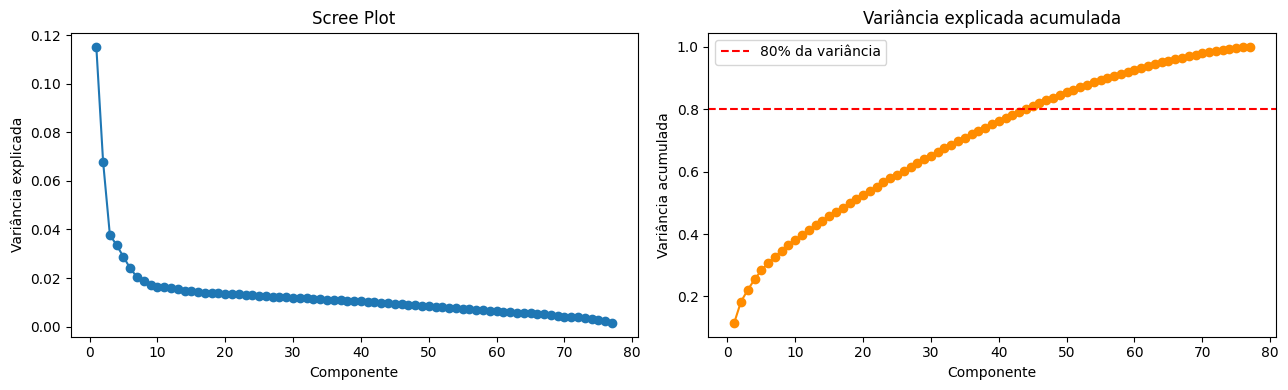

Critério de Kaiser (autovalor > 1): 22 componentes
Componentes necessários para explicar >= 80% da variância: 44

Com n_components=5 (valor atual do notebook), a variância explicada acumulada é 28.3%


In [4]:
# Verificação do número de componentes
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
eigenvalues = pca_full.explained_variance_

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(range(1, len(explained) + 1), explained, 'o-')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Variância explicada')
axes[0].set_title('Scree Plot')

axes[1].plot(range(1, len(cumulative) + 1), cumulative, 'o-', color='darkorange')
axes[1].axhline(y=0.80, color='red', linestyle='--', label='80% da variância')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Variância acumulada')
axes[1].set_title('Variância explicada acumulada')
axes[1].legend()

plt.tight_layout()
plt.show()

n_kaiser = int((eigenvalues > 1).sum())
n_80pct = int(np.argmax(cumulative >= 0.80) + 1)

print(f"Critério de Kaiser (autovalor > 1): {n_kaiser} componentes")
print(f"Componentes necessários para explicar >= 80% da variância: {n_80pct}")
print(f"\nCom n_components=5 (valor atual do notebook), a variância explicada acumulada é "
      f"{cumulative[4]*100:.1f}%")


### Resultados

In [5]:

print("\n--- AS VARIÁVEIS MAIS RELEVANTES PARA CLUSTERING ---")
print("\nVariáveis que lideram o Eixo 1 (Geralmente Eixo Social/Desigualdade):")
print(loadings['PC1'].abs().sort_values(ascending=False).head(3))

print("\nVariáveis que lideram o Eixo 2 (Geralmente Capacidade Institucional/Urbana):")
print(loadings['PC2'].abs().sort_values(ascending=False).head(3))

print("\nVariáveis que lideram o Eixo 3:")
print(loadings['PC3'].abs().sort_values(ascending=False).head(3))

print("\nVariáveis que lideram o Eixo 4:")
print(loadings['PC4'].abs().sort_values(ascending=False).head(3))

print("\nVariáveis que lideram o Eixo 5:")
print(loadings['PC5'].abs().sort_values(ascending=False).head(3))



--- AS VARIÁVEIS MAIS RELEVANTES PARA CLUSTERING ---

Variáveis que lideram o Eixo 1 (Geralmente Eixo Social/Desigualdade):
SDG1_1_P_F_CU      0.266725
SDG1_4_R_1_4_SM    0.257149
SDG2_8_AGR_FAM     0.255162
Name: PC1, dtype: float64

Variáveis que lideram o Eixo 2 (Geralmente Capacidade Institucional/Urbana):
SDG17_3_P_RC_TRB    0.264362
SDG13_4_PREV        0.254178
SDG11_5_DMC_FVL     0.230265
Name: PC2, dtype: float64

Variáveis que lideram o Eixo 3:
SDG15_2_FLOR      0.271754
SDG8_2_OCP_INF    0.256107
SDG7_3_VNLENER    0.255753
Name: PC3, dtype: float64

Variáveis que lideram o Eixo 4:
SDG5_7_JV_NENT      0.306232
SDG5_3_M_JV_NENT    0.273532
SDG17_1_INVST_PB    0.268768
Name: PC4, dtype: float64

Variáveis que lideram o Eixo 5:
SDG16_3_M_ARM_FG    0.466642
SDG16_1_OB_HM       0.418318
SDG10_3_RZHOM       0.340235
Name: PC5, dtype: float64


#### Checagem de sobreposição entre eixos e consolidação do subconjunto final


In [8]:
# Checagem de sobreposição entre as variáveis selecionadas nos diferentes eixos
top_n = 3
selected_by_pc = {
    pc: loadings[pc].abs().sort_values(ascending=False).head(top_n).index.tolist()
    for pc in ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
}

all_selected = [v for lst in selected_by_pc.values() for v in lst]
from collections import Counter
counts = Counter(all_selected)
duplicates = {v: c for v, c in counts.items() if c > 1}

final_vars = sorted(set(all_selected))

print(f"Total de variáveis selecionadas (com repetição): {len(all_selected)}")
print(f"Total de variáveis únicas: {len(final_vars)}")

if duplicates:
    print("\nVariáveis que aparecem em mais de um eixo (redundância entre componentes):")
    for v, c in duplicates.items():
        print(f"  - {v}: aparece em {c} eixos")
else:
    print("\nNenhuma variável repetida entre eixos.")

print(f"\nSubconjunto final de variáveis para o clustering ({len(final_vars)}):")
for v in final_vars:
    print(f"  - {v}")


Total de variáveis selecionadas (com repetição): 15
Total de variáveis únicas: 15

Nenhuma variável repetida entre eixos.

Subconjunto final de variáveis para o clustering (15):
  - SDG10_3_RZHOM
  - SDG11_5_DMC_FVL
  - SDG13_4_PREV
  - SDG15_2_FLOR
  - SDG16_1_OB_HM
  - SDG16_3_M_ARM_FG
  - SDG17_1_INVST_PB
  - SDG17_3_P_RC_TRB
  - SDG1_1_P_F_CU
  - SDG1_4_R_1_4_SM
  - SDG2_8_AGR_FAM
  - SDG5_3_M_JV_NENT
  - SDG5_7_JV_NENT
  - SDG7_3_VNLENER
  - SDG8_2_OCP_INF


#### Validação: o subconjunto selecionado separa clusters tão bem quanto os componentes PCA?

Selecionar variáveis originais via loading do PCA prioriza interpretabilidade, mas não garante a melhor separação de clusters. Comparamos aqui o *silhouette score* usando o subconjunto final de variáveis versus usar os 5 componentes PCA diretamente, para diferentes números de clusters.


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_final_scaled = StandardScaler().fit_transform(X_filtered[final_vars])
X_pca_scores = pca.transform(X_scaled)  # scores nos 5 componentes já ajustados

resultados = []
for k in range(2, 7):
    km_vars = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_final_scaled)
    km_pca = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca_scores)
    sil_vars = silhouette_score(X_final_scaled, km_vars.labels_)
    sil_pca = silhouette_score(X_pca_scores, km_pca.labels_)
    resultados.append({
        'k': k,
        'silhouette_variaveis_selecionadas': round(sil_vars, 4),
        'silhouette_componentes_pca': round(sil_pca, 4)
    })

pd.DataFrame(resultados).set_index('k')


,silhouette_variaveis_selecionadas,silhouette_componentes_pca
k,,
2,0.2109,0.2949
3,0.1984,0.2621
4,0.1746,0.2562
5,0.1702,0.2459
6,0.1761,0.2405
